# Kryptonite-3.0: mock paper experiments

This notebook reproduces Figures 1 to 3 of *Kryptonite-3.0: The Final End to Machine Learning Hype?* from the files in `Datasets/` and the KryptoNet-40 weights in `kryptonet40.pt`. Everything runs on a laptop CPU. Figure 1 needs about 4 GB of memory and takes 5 to 20 minutes, depending on the laptop.

In [1]:
import copy
import warnings
from math import comb
import numpy as np
import scipy.linalg as sla
import torch
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LogisticRegression
from kryptonet import load_kryptonet

# numpy 2.0 with Apple's Accelerate library raises spurious floating-point warnings in matrix products;
# the results are correct.
warnings.filterwarnings("ignore", message=".*encountered in matmul")
try:
    import scienceplots  # noqa: F401
    plt.style.use(["science", "no-latex"])
except ImportError:
    pass
plt.rcParams.update({"font.size": 9, "axes.titlesize": 10, "axes.labelsize": 9, "legend.fontsize": 8})
COLORS = {20: "#4878d0", 30: "#ee854a", 40: "#6acc64"}
NS = (20, 30, 40)
TARGET = 0.90


def load(name):
    return np.load(f"Datasets/{name}-X.npy"), np.load(f"Datasets/{name}-y.npy")


def split(X, y):
    """60% train, 20% validation, 20% test."""
    X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, random_state=42)
    X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)
    return X_train, y_train, X_test, y_test


def poly_logreg(X_train, y_train, X_test, y_test, degree):
    """Logistic regression on explicit polynomial features."""
    poly = PolynomialFeatures(degree)
    logreg = LogisticRegression(max_iter=100, solver="sag", C=0.85)
    logreg.fit(poly.fit_transform(X_train), y_train)
    return float(logreg.score(poly.transform(X_test), y_test))

## Figure 1: polynomial logistic regression up to degree 10

Explicit polynomial features stop fitting in memory beyond degree 4, so every degree is fitted in its dual form with the kernel trick (Section 3.2 of the paper). The kernel is the inner product of `PolynomialFeatures(degree)` between two inputs rounded to bits, normalised so that k(x, x) = 1, and the model is trained with the same regularisation constant (C = 0.85) by Newton's method.

n=20 degree=1 features=21 accuracy=0.503


n=20 degree=2 features=231 accuracy=0.553


n=20 degree=3 features=1,771 accuracy=0.556


n=20 degree=4 features=10,626 accuracy=0.573


n=20 degree=5 features=53,130 accuracy=0.570


...

n=40 degree=6 features=9,366,819 accuracy=0.541


n=40 degree=7 features=62,891,499 accuracy=0.525


n=40 degree=8 features=377,348,994 accuracy=0.541


n=40 degree=9 features=2,054,455,634 accuracy=0.525


n=40 degree=10 features=10,272,278,170 accuracy=0.541


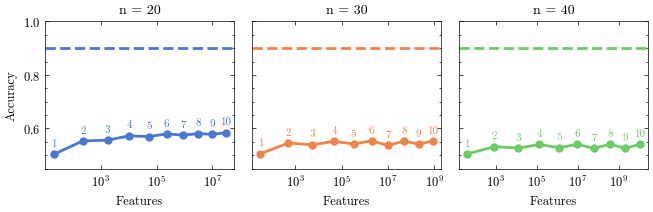

In [2]:
def agreements(X1, X2, n):
    """Number of agreeing bits between every pair of rows, after rounding the inputs to bits."""
    B1, B2 = np.sign(X1).astype(np.float32), np.sign(X2).astype(np.float32)
    return np.rint((n + B1 @ B2.T) / 2).astype(np.uint8)


def polyfeatures_kernel_table(n, degree):
    """phi(x).phi(x') for PolynomialFeatures(degree) on +-1 bits, indexed by the number m of agreeing bits."""
    table = np.zeros(n + 1)
    for s in range(degree + 1):
        weight = comb(n + (degree - s) // 2, n)
        e_s = [sum(comb(m, a) * comb(n - m, s - a) * (-1) ** (s - a) for a in range(s + 1)) for m in range(n + 1)]
        table += weight * np.array(e_s, dtype=float)
    return table / table[n]


def kernel_logreg(K, y, C=0.85, iters=30, tol=1e-6):
    """C * sum(log-loss) + ||w||^2 / 2 in the dual, by Newton's method (Rasmussen & Williams, Alg. 3.1)."""
    t = y.astype(np.float64); sign = 2 * t - 1
    a, f = np.zeros(len(t), np.float32), np.zeros(len(t))
    obj = C * len(t) * np.log(2)
    for _ in range(iters):
        pi = 1 / (1 + np.exp(-f))
        W = C * pi * (1 - pi); sW = np.sqrt(W).astype(np.float32)
        B = K * sW[:, None]; B *= sW[None, :]; B[np.diag_indices_from(B)] += 1
        L = sla.cholesky(B, lower=True, overwrite_a=True, check_finite=False)
        del B
        b = (W * f + C * (t - pi)).astype(np.float32)
        v = sla.solve_triangular(L, sW * (K @ b), lower=True, check_finite=False)
        a_new = b - sW * sla.solve_triangular(L, v, lower=True, trans="T", check_finite=False)
        del L
        f_new = (K @ a_new).astype(np.float64)
        new = C * np.logaddexp(0, -sign * f_new).sum() + 0.5 * float(a_new @ f_new)
        for _ in range(5):
            if new <= obj:
                break
            a_new, f_new = (a + a_new) / 2, (f + f_new) / 2
            new = C * np.logaddexp(0, -sign * f_new).sum() + 0.5 * float(a_new @ f_new)
        done = abs(obj - new) < tol * abs(new)
        a, f, obj = a_new, f_new, new
        if done:
            break
    return a


fig1 = {}
for n in NS:
    X_train, y_train, X_test, y_test = split(*load(f"kryptonite-{n}"))
    M_train, M_test = agreements(X_train, X_train, n), agreements(X_test, X_train, n)
    fig1[n] = []
    for d in range(1, 11):
        table = polyfeatures_kernel_table(n, d).astype(np.float32)
        a = kernel_logreg(table[M_train], y_train)
        acc = float(((table[M_test] @ a > 0).astype(int) == y_test).mean())
        fig1[n].append((d, comb(n + d, d), acc))
        print(f"n={n} degree={d} features={comb(n + d, d):,} accuracy={acc:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(6.75, 2.3), sharey=True)
for ax, n in zip(axes, NS):
    degrees, feats, accs = zip(*fig1[n])
    ax.plot(feats, accs, marker="o", color=COLORS[n], lw=2, ms=5)
    for d, x, acc in fig1[n]:
        ax.annotate(str(d), (x, acc), textcoords="offset points", xytext=(0, 6), ha="center", color=COLORS[n], fontsize=8)
    ax.axhline(TARGET, color=COLORS[n], ls="--", lw=2)
    ax.set_xscale("log"); ax.set_title(f"n = {n}"); ax.set_xlabel("Features")
axes[0].set_ylabel("Accuracy"); axes[0].set_ylim(0.45, 1.0)
fig.tight_layout(); plt.show()

## Figure 2: more training data

Quadratic logistic regression on explicit features, trained on 25%, 50% and 100% of each training split.

n=20 training points=1800 accuracy=0.522


n=20 training points=3600 accuracy=0.532


n=20 training points=7200 accuracy=0.548


n=30 training points=3000 accuracy=0.519


n=30 training points=6000 accuracy=0.522


n=30 training points=12000 accuracy=0.540


n=40 training points=4800 accuracy=0.517


n=40 training points=9600 accuracy=0.523


n=40 training points=19200 accuracy=0.528


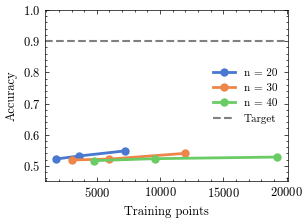

In [3]:
fig2 = {}
for n in NS:
    X_train, y_train, X_test, y_test = split(*load(f"kryptonite-{n}"))
    fig2[n] = []
    for frac in (0.25, 0.5, 1.0):
        m = int(frac * len(y_train))
        acc = poly_logreg(X_train[:m], y_train[:m], X_test, y_test, 2)
        fig2[n].append((m, acc))
        print(f"n={n} training points={m} accuracy={acc:.3f}")

fig, ax = plt.subplots(figsize=(3.25, 2.4))
for n in NS:
    sizes, accs = zip(*fig2[n])
    ax.plot(sizes, accs, marker="o", color=COLORS[n], lw=2, ms=5, label=f"n = {n}")
ax.axhline(TARGET, color="gray", ls="--", lw=1.5, label="Target")
ax.set_xlabel("Training points"); ax.set_ylabel("Accuracy"); ax.set_ylim(0.45, 1.0)
ax.legend(loc="center right", frameon=False)
fig.tight_layout(); plt.show()

## Figure 3: KryptoNet-40 on Kryptonite-40-Adapt

KryptoNet-40 used zero-shot, and with its hidden layers frozen under a retrained linear output layer (linear probe) or a one-hidden-layer MLP head (MLP probe). 20% of Kryptonite-40-Adapt is held out for testing.

{'Zero-shot': 0.48125, 'Linear probe': 0.495, 'MLP probe': 0.46375}


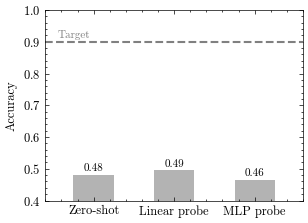

In [4]:
def accuracy(net, X, y):
    net.eval()
    with torch.no_grad():
        return float(((net(torch.from_numpy(X)).squeeze(1) > 0).long().numpy() == y).mean())


def fit(net, X, y, params, lr, epochs=300, patience=40, bs=128):
    """Adam on `params` with early stopping on a 20% validation split; restores the best weights."""
    X, y = torch.from_numpy(X), torch.from_numpy(y).float()
    perm = torch.randperm(len(y)); nv = len(y) // 5
    Xv, yv, Xa, ya = X[perm[:nv]], y[perm[:nv]], X[perm[nv:]], y[perm[nv:]]
    opt = torch.optim.Adam(params, lr=lr)
    best, state, since = -1.0, None, 0
    for _ in range(epochs):
        net.train(); p = torch.randperm(len(ya))
        for i in range(0, len(ya), bs):
            bi = p[i:i + bs]
            loss = torch.nn.functional.binary_cross_entropy_with_logits(net(Xa[bi]).squeeze(1), ya[bi])
            opt.zero_grad(); loss.backward(); opt.step()
        net.eval()
        with torch.no_grad():
            va = float(((net(Xv).squeeze(1) > 0).float() == yv).float().mean())
        if va > best:
            best, since, state = va, 0, copy.deepcopy(net.state_dict())
        else:
            since += 1
            if since >= patience:
                break
    net.load_state_dict(state)
    return net


X, y = load("kryptonite-40-adapt")
X_pool, X_test, y_pool, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
base = load_kryptonet("kryptonet40.pt")
torch.manual_seed(0)
fig3 = {"Zero-shot": accuracy(base, X_test, y_test)}

probe = copy.deepcopy(base)
for p in probe.parameters():
    p.requires_grad_(False)
probe[-1] = torch.nn.Linear(probe[-1].in_features, 1)
fig3["Linear probe"] = accuracy(fit(probe, X_pool, y_pool, probe[-1].parameters(), lr=1e-2), X_test, y_test)

mlp_probe = copy.deepcopy(probe)
width = mlp_probe[-1].in_features
mlp_probe[-1] = torch.nn.Sequential(torch.nn.Linear(width, width), torch.nn.ReLU(), torch.nn.Linear(width, 1))
fig3["MLP probe"] = accuracy(fit(mlp_probe, X_pool, y_pool, mlp_probe[-1].parameters(), lr=1e-3), X_test, y_test)
print(fig3)

fig, ax = plt.subplots(figsize=(3.25, 2.4))
names, accs = list(fig3), list(fig3.values())
ax.bar(range(len(names)), accs, color="0.7", width=0.5)
for i, acc in enumerate(accs):
    ax.text(i, acc + 0.012, f"{acc:.2f}", ha="center", fontsize=8)
ax.axhline(TARGET, color="gray", ls="--", lw=1.5)
ax.text(-0.45, TARGET + 0.012, "Target", ha="left", fontsize=8, color="gray")
ax.set_xticks(range(len(names))); ax.set_xticklabels(names); ax.set_xlim(-0.6, len(names) - 0.4)
ax.set_ylabel("Accuracy"); ax.set_ylim(0.4, 1.0)
fig.tight_layout(); plt.show()